In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 6.0)

In [5]:
df = pd.read_csv("/Users/riya/Desktop/IITGN/Build2/week-6--Build-Week-Project-/week-6/documents/build2-starter/notebooks/hotels.csv")

In [6]:
df.shape

(119390, 32)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [8]:
missing_values = df.isnull().sum()
print(missing_values)

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [9]:
duplicate_values = df.duplicated().sum()
print(duplicate_values)

31994


In [12]:
# Observation: 'agent' and 'company' have missing values. I think NaN just
# means the booking didn't come through an agent / company, so I won't
# treat it as a mistake. Duplicates exist too, but there is no booking ID,
# so two identical rows could still be two real bookings. I'm leaving them in.

In [10]:
df["nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"].fillna(0) + df["babies"]


In [14]:
print("Bookings with 0 guests :", (df["total_guests"] == 0).sum())
print("Bookings with 0 nights :", (df["nights"] == 0).sum())
print("Rows with price <= 0   :", (df["adr"] <= 0).sum())
print("Highest price (adr)    :", df["adr"].max())

Bookings with 0 guests : 180
Bookings with 0 nights : 715
Rows with price <= 0   : 1960
Highest price (adr)    : 5400.0


In [15]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

In [12]:
print("\n--- Summary of numeric columns ---")
print(df[["lead_time", "nights", "total_guests", "adr",
          "booking_changes", "total_of_special_requests"]].describe().round(1))



--- Summary of numeric columns ---
       lead_time    nights  total_guests       adr  booking_changes  \
count   119390.0  119390.0      119390.0  119390.0         119390.0   
mean       104.0       3.4           2.0     101.8              0.2   
std        106.9       2.6           0.7      50.5              0.7   
min          0.0       0.0           0.0      -6.4              0.0   
25%         18.0       2.0           2.0      69.3              0.0   
50%         69.0       3.0           2.0      94.6              0.0   
75%        160.0       4.0           2.0     126.0              0.0   
max        737.0      69.0          55.0    5400.0             21.0   

       total_of_special_requests  
count                   119390.0  
mean                         0.6  
std                          0.8  
min                          0.0  
25%                          0.0  
50%                          0.0  
75%                          1.0  
max                          5.0  


In [13]:
cancel_rate = df["is_canceled"].mean()
print(f"\nOverall cancellation rate: {cancel_rate:.1%}")


Overall cancellation rate: 37.0%


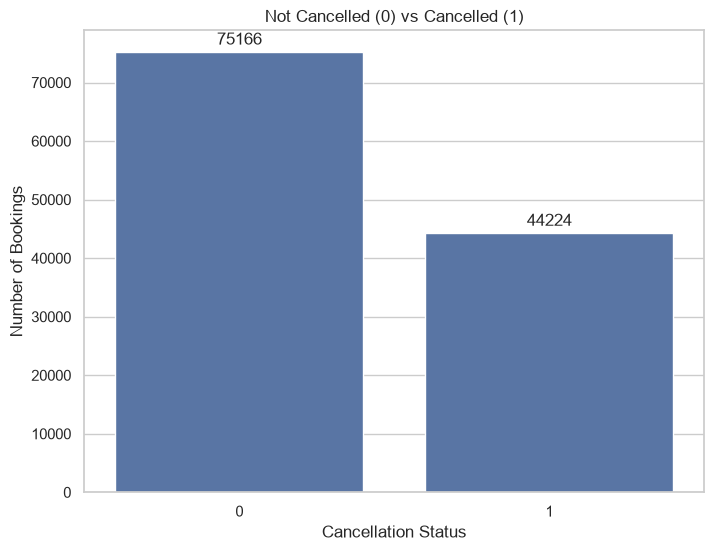

In [16]:
ax = sns.countplot(x="is_canceled", data=df)
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Not Cancelled (0) vs Cancelled (1)")
plt.xlabel("Cancellation Status")
plt.ylabel("Number of Bookings")
plt.show()


Cancellation rate by hotel:
hotel
City Hotel      0.417
Resort Hotel    0.278
Name: is_canceled, dtype: float64


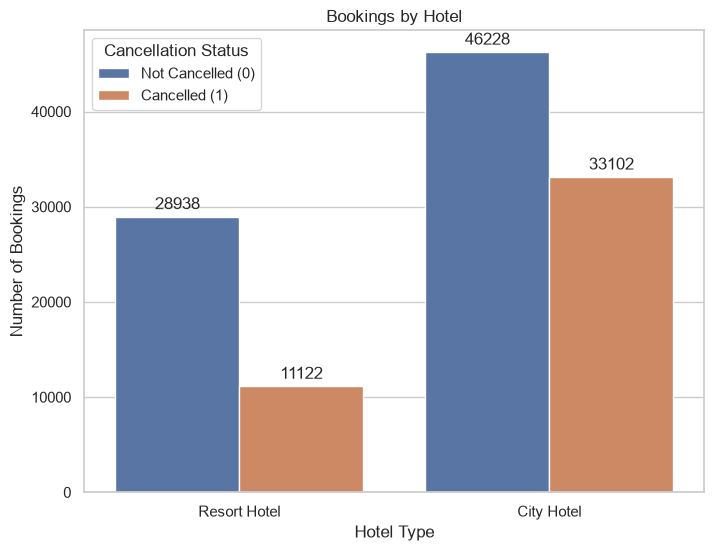

In [17]:
print("\nCancellation rate by hotel:")
print(df.groupby("hotel")["is_canceled"].mean().round(3))

ax = sns.countplot(x="hotel", hue="is_canceled", data=df)

# Add labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title("Bookings by Hotel")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.legend(title="Cancellation Status", labels=["Not Cancelled (0)", "Cancelled (1)"])

plt.show()

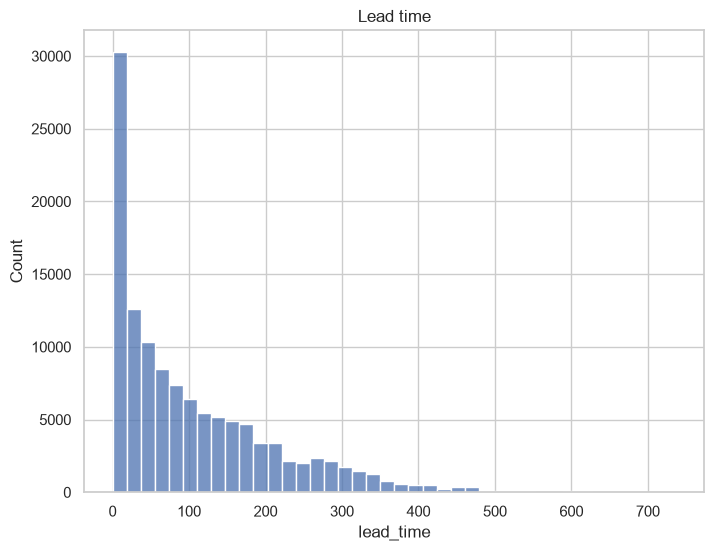

In [18]:
sns.histplot(df["lead_time"], bins=40)
plt.title("Lead time")
plt.show()

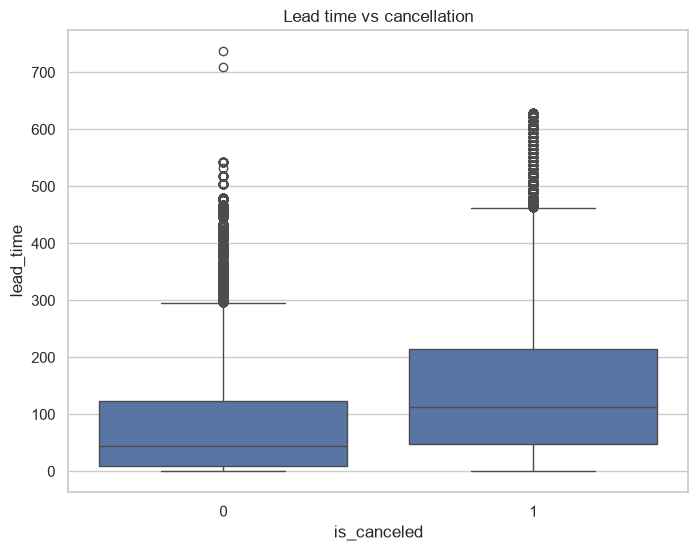

In [19]:
sns.boxplot(x="is_canceled", y="lead_time", data=df)
plt.title("Lead time vs cancellation")
plt.show()


Cancellation rate by lead time (days):
lead_group
0-7        0.096
8-30       0.279
31-90      0.377
91-180     0.447
181-365    0.555
365+       0.677
Name: is_canceled, dtype: float64


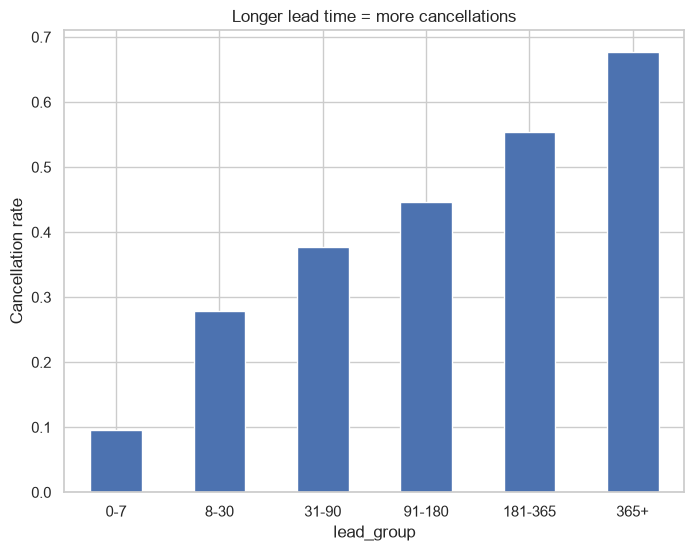

In [21]:
df["lead_group"] = pd.cut(df["lead_time"],
                          bins=[-1, 7, 30, 90, 180, 365, 1000],
                          labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
print("\nCancellation rate by lead time (days):")
print(df.groupby("lead_group", observed=True)["is_canceled"].mean().round(3))

df.groupby("lead_group", observed=True)["is_canceled"].mean().plot(kind="bar")
plt.ylabel("Cancellation rate")
plt.title("Longer lead time = more cancellations")
plt.xticks(rotation=0)
plt.show()


Cancellation rate by month:
arrival_date_month
January      0.305
February     0.334
March        0.322
April        0.408
May          0.397
June         0.415
July         0.375
August       0.378
September    0.392
October      0.380
November     0.312
December     0.350
Name: is_canceled, dtype: float64


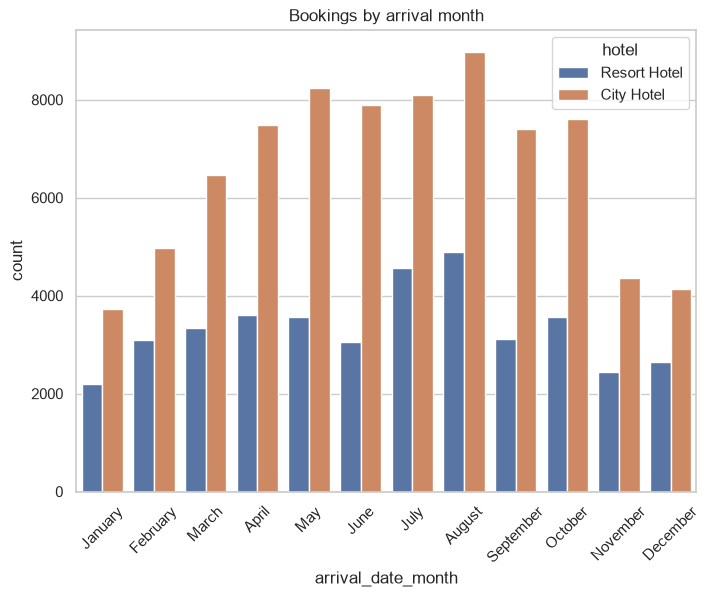

In [22]:
month_cancel = df.groupby("arrival_date_month")["is_canceled"].mean().reindex(months)
print("\nCancellation rate by month:")
print(month_cancel.round(3))

sns.countplot(x="arrival_date_month", data=df, order=months, hue="hotel")
plt.xticks(rotation=45)
plt.title("Bookings by arrival month")
plt.show()

In [23]:
# Dropping zero prices and the extreme ones, only for these charts
normal_prices = df[(df["adr"] > 0) & (df["adr"] < 500)]

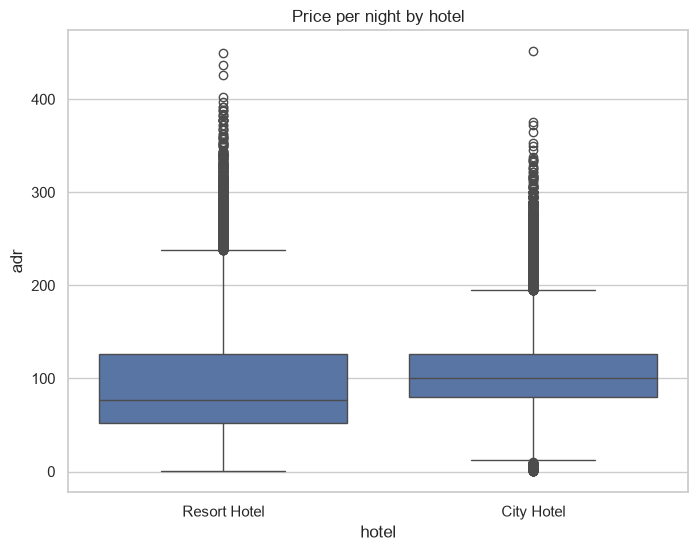

In [24]:
sns.boxplot(x="hotel", y="adr", data=normal_prices)
plt.title("Price per night by hotel")
plt.show()

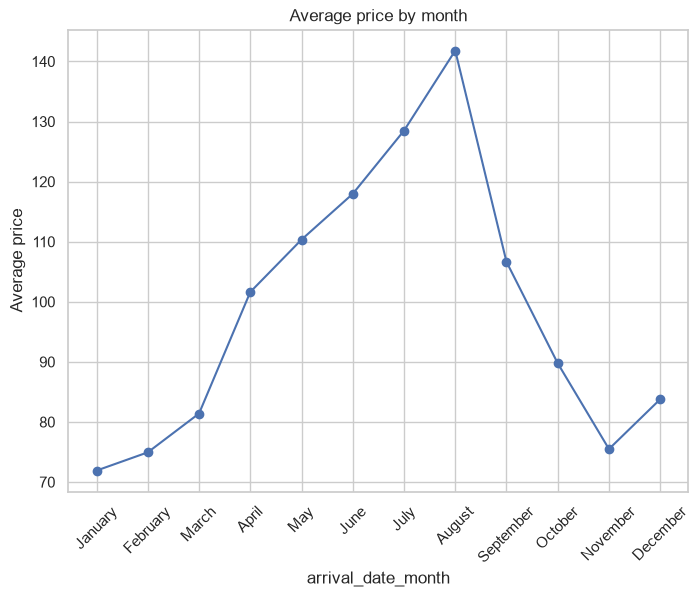

In [25]:
price_by_month = normal_prices.groupby("arrival_date_month")["adr"].mean().reindex(months)
price_by_month.plot(marker="o")
plt.xticks(range(12), months, rotation=45)
plt.ylabel("Average price")
plt.title("Average price by month")
plt.show()



Cancellation rate by deposit_type:
deposit_type
Non Refund    0.994
No Deposit    0.284
Refundable    0.222
Name: is_canceled, dtype: float64


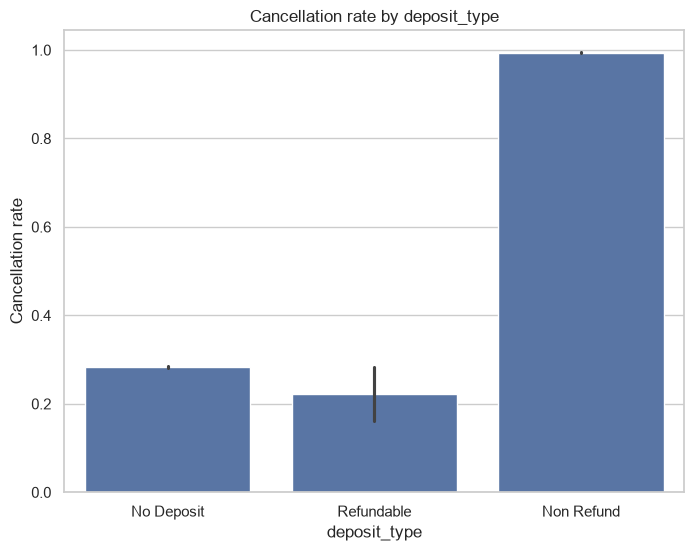


Cancellation rate by market_segment:
market_segment
Undefined        1.000
Groups           0.611
Online TA        0.367
Offline TA/TO    0.343
Aviation         0.219
Corporate        0.187
Direct           0.153
Complementary    0.131
Name: is_canceled, dtype: float64


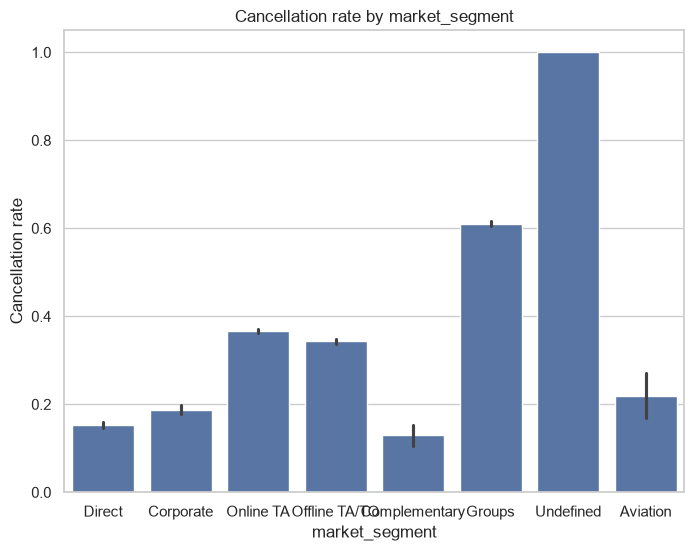


Cancellation rate by customer_type:
customer_type
Transient          0.407
Contract           0.310
Transient-Party    0.254
Group              0.102
Name: is_canceled, dtype: float64


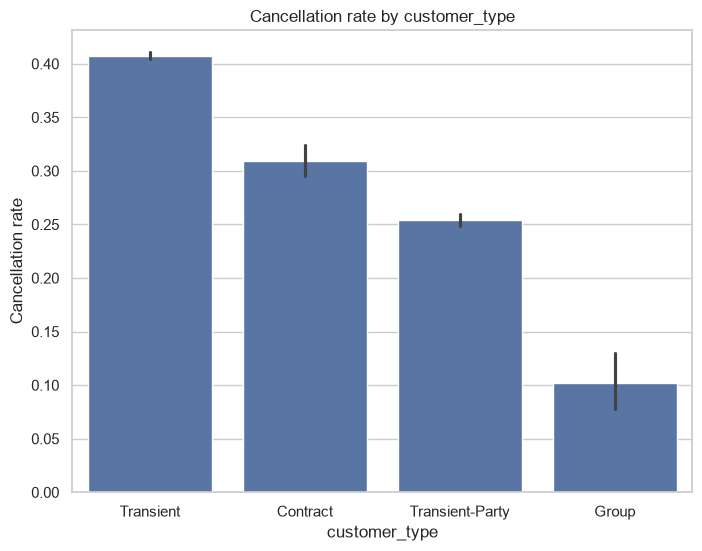

In [26]:
for col in ["deposit_type", "market_segment", "customer_type"]:
    print(f"\nCancellation rate by {col}:")
    print(df.groupby(col)["is_canceled"].mean().round(3).sort_values(ascending=False))

    sns.barplot(x=col, y="is_canceled", data=df)
    plt.xticks(rotation=0)
    plt.ylabel("Cancellation rate")
    plt.title(f"Cancellation rate by {col}")
    plt.show()

In [27]:
df["requests"] = df["total_of_special_requests"].clip(upper=3)
print("\nCancellation rate by number of special requests (3 means 3 or more):")
print(df.groupby("requests")["is_canceled"].mean().round(3))



Cancellation rate by number of special requests (3 means 3 or more):
requests
0    0.477
1    0.220
2    0.221
3    0.168
Name: is_canceled, dtype: float64


In [28]:
print("\nCancellation rate when parking is needed:")
print(df.groupby(df["required_car_parking_spaces"] > 0)["is_canceled"].mean().round(3))


Cancellation rate when parking is needed:
required_car_parking_spaces
False    0.395
True     0.000
Name: is_canceled, dtype: float64


In [44]:
# Observation: 'Non Refund' deposit has an almost 100% cancel rate, which
# looks strange - I'd double check how that column was filled in.
# Guests with special requests or a parking need rarely cancel.




Top 10 countries:
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64


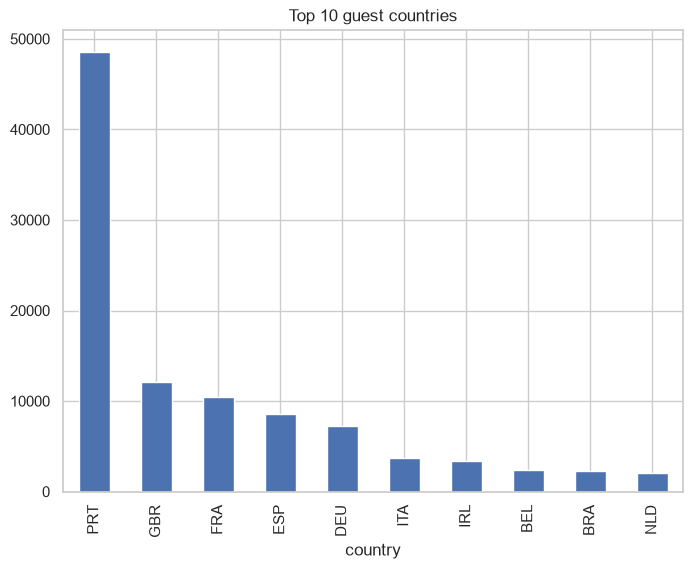

In [29]:
top_countries = df["country"].value_counts().head(10)
print("\nTop 10 countries:")
print(top_countries)

top_countries.plot(kind="bar")
plt.title("Top 10 guest countries")
plt.show()

In [46]:
import plotly.express as px

df["country"] = df["country"].replace({"CN": "CHN"})
map_data = df[df["country"] != "Unknown"]


country_counts = map_data["country"].value_counts().reset_index()
country_counts.columns = ["country", "bookings"]

fig = px.choropleth(
    country_counts,
    locations="country",          # column with the country codes
    locationmode="ISO-3",         # tells plotly these are 3-letter codes
    color="bookings",             # darker colour = more bookings
    color_continuous_scale="Blues",
    title="Hotel bookings by guest country",
)
fig.update_layout(geo=dict(showframe=False, projection_type="natural earth"))
fig.show()

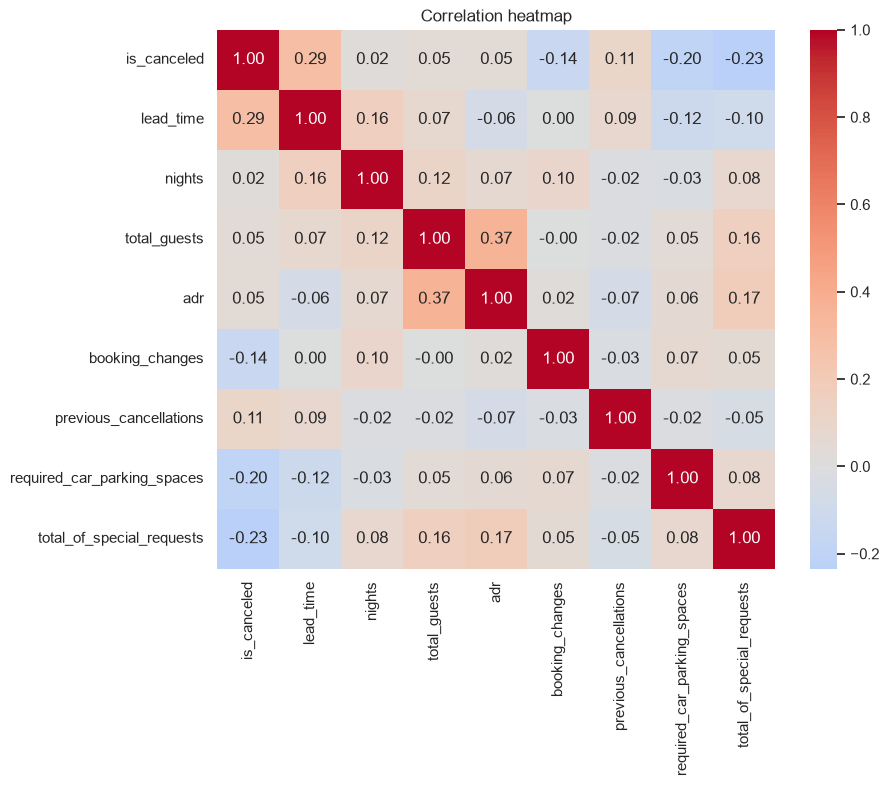


Correlation with is_canceled:
total_of_special_requests     -0.234658
required_car_parking_spaces   -0.195498
booking_changes               -0.144381
nights                         0.017779
total_guests                   0.046522
adr                            0.047557
previous_cancellations         0.110133
lead_time                      0.293123
Name: is_canceled, dtype: float64


In [30]:
cols = ["is_canceled", "lead_time", "nights", "total_guests", "adr",
        "booking_changes", "previous_cancellations",
        "required_car_parking_spaces", "total_of_special_requests"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

print("\nCorrelation with is_canceled:")
print(df[cols].corr()["is_canceled"].drop("is_canceled").sort_values())

In [48]:
# Observation: nothing is strongly correlated with cancellation by itself.
# Lead time and previous cancellations push it up; special requests and
# parking pull it down.

In [32]:
print("\nreservation_status vs is_canceled:")
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))

# Observation: 'Canceled' and 'No-Show' are always 1, 'Check-Out' is always 0.
# So reservation_status (and its date) basically contain the answer.
# I must remove them before building any model.


# ---------------------------------------------------------------
# Wrap-up
# ---------------------------------------------------------------
print("\n===== Main takeaways =====")
print(f"1. About {cancel_rate:.0%} of bookings are cancelled.")
print("2. City Hotel is busier and has more cancellations than Resort Hotel.")
print("3. Longer lead time -> higher chance of cancellation.")
print("4. Summer is peak season, with higher prices.")
print("5. Deposit type, market segment and special requests matter a lot.")
print("6. Data to handle: zero-guest rows, zero/extreme prices, duplicates,")
print("   missing agent/company, and the reservation_status leak.")


reservation_status vs is_canceled:
is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207

===== Main takeaways =====
1. About 37% of bookings are cancelled.
2. City Hotel is busier and has more cancellations than Resort Hotel.
3. Longer lead time -> higher chance of cancellation.
4. Summer is peak season, with higher prices.
5. Deposit type, market segment and special requests matter a lot.
6. Data to handle: zero-guest rows, zero/extreme prices, duplicates,
   missing agent/company, and the reservation_status leak.
